In [1]:
from tqdm import tqdm
from sklearn.metrics import roc_curve
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import roc_auc_score, classification_report

In [2]:
import os
import glob
import torch
import torchaudio
import numpy as np
import pandas as pd
import torch.nn as nn
import seaborn as sns
import torch.optim as optim
import matplotlib.pyplot as plt
import torchaudio.transforms as T

In [3]:
class AudioAnomalyDataset(Dataset):
    def __init__(self, audio_dir, target_sr=16000, mean=None, std=None):
        self.audio_dir = audio_dir
        self.target_sr = target_sr
        self.file_paths = sorted(glob.glob(os.path.join(audio_dir, "*.wav")))
        self.mean = mean
        self.std = std

        if len(self.file_paths) == 0:
            raise RuntimeError(f"No .wav files found in {audio_dir}.")

    def __len__(self):
        return len(self.file_paths)

    def __getitem__(self, idx):
        file_path = self.file_paths[idx]
        waveform, sample_rate = torchaudio.load(file_path)

        if waveform.shape[0] > 1:
            waveform = torch.mean(waveform, dim=0, keepdim=True)
        if sample_rate != self.target_sr:
            resampler = T.Resample(orig_freq=sample_rate, new_freq=self.target_sr)
            waveform = resampler(waveform)

        mel_transformer = T.MelSpectrogram(sample_rate=self.target_sr, n_fft=1024, hop_length=512, n_mels=64)
        mel_spec = mel_transformer(waveform)

        log_mel = torch.log(mel_spec + 1e-9)

        # Global Z-Score normalization instead of sample-wise min-max scaling
        mean_val = self.mean if self.mean is not None else -4.5
        std_val = self.std if self.std is not None else 2.0
        normalized = (log_mel - mean_val) / (std_val + 1e-9)

        if normalized.shape[-1] > 64:
            normalized = normalized[..., :64]
        else:
            normalized = nn.functional.pad(normalized, (0, 64 - normalized.shape[-1]))

        return normalized

In [26]:
class AudioVAE(nn.Module):
    def __init__(self, input_shape=64, latent_dim=16):
        super(AudioVAE, self).__init__()
        self.input_shape = input_shape
        self.latent_dim = latent_dim
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(16, 32, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),
            nn.Flatten()
        )

        flat_features = 64 * (input_shape // 8) * (input_shape // 8)

        self.fc_mu = nn.Linear(flat_features, latent_dim)
        self.fc_logvar = nn.Linear(flat_features, latent_dim)
        self.decoder_input = nn.Linear(latent_dim, flat_features)
        self.decoder = nn.Sequential(
            nn.Unflatten(1, (64, input_shape // 8, input_shape // 8)),
            nn.ConvTranspose2d(64, 32, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(32, 16, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(16, 1, kernel_size=3, stride=2, padding=1, output_padding=1)
        ) # Removed Sigmoid to support unbounded Z-score target ranges

    def encode(self, x):
        hidden = self.encoder(x)
        mu = self.fc_mu(hidden)
        return mu, self.fc_logvar(hidden)

    def reparameterize(self, mu, logvar):
        eps = torch.randn_like(torch.exp(0.5 * logvar))
        return mu + eps * torch.exp(0.5 * logvar)

    def decode(self, z):
        hidden = self.decoder_input(z)
        reconstruction = self.decoder(hidden)
        return reconstruction

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar

def vae_loss_fn(recon_x, x, mu, logvar, beta=0.01):
    recon_loss = nn.functional.mse_loss(recon_x, x, reduction='mean')
    kld_loss = -0.5 * torch.mean(1 + logvar - mu.pow(2) - logvar.exp())
    return recon_loss + (beta * kld_loss)

In [28]:
def compute_anomaly_score(model, spectrogram_tensor):
    """MSE reconstruction score supporting both VAE and CAE return types"""
    model.eval()
    with torch.no_grad():
        outputs = model(spectrogram_tensor)
        # If model returns (reconstruction, mu, logvar)
        if isinstance(outputs, tuple):
            recon = outputs[0]
        else:
            recon = outputs
        error = nn.functional.mse_loss(recon, spectrogram_tensor, reduction='mean')
    return error.item()

def calculate_threshold(model, validation_loader, device, percentile=95):
    """
    Finds reconstruction score threshold on clean/normal validation data.
    Any score above the chosen percentile will flag an anomaly.
    """
    model.eval()
    scores = []
    print(f"Calculating dynamic threshold using the {percentile}th percentile...")

    for batch in validation_loader:
        batch = batch.to(device)
        for sample in batch:
            score = compute_anomaly_score(model, sample.unsqueeze(0))
            scores.append(score)
    return np.percentile(scores, percentile)

def evaluate_pipeline(model, test_normal_loader, test_anomaly_loader, threshold, device):
    """
    Calculates ROC-AUC metric and generates a classification report
    using mixed validation sets.
    """
    y_true = []
    y_scores = []

    # 0 = Normal, 1 = Anomaly
    # Process known normal files
    for batch in test_normal_loader:
        batch = batch.to(device)
        for sample in batch:
            score = compute_anomaly_score(model, sample.unsqueeze(0))
            y_scores.append(score)
            y_true.append(0)

    # Process known anomaly files
    for batch in test_anomaly_loader:
        batch = batch.to(device)
        for sample in batch:
            score = compute_anomaly_score(model, sample.unsqueeze(0))
            y_scores.append(score)
            y_true.append(1)

    y_true = np.array(y_true)
    y_scores = np.array(y_scores)
    y_pred = (y_scores > threshold).astype(int)

    # Print Metrics Output
    auc = roc_auc_score(y_true, y_scores)
    print("\n================ EVALUATION METRICS ================")
    print(f"Calculated ROC-AUC Score: {auc:.4f}")
    print(f"Decision Boundary Threshold: {threshold:.6f}")
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, target_names=["Normal", "Anomaly"], zero_division=0))

In [29]:
if __name__ == "__main__":
    # Create fake directory paths
    TRAIN_DIR = "data/train_normal"
    VAL_NORMAL_DIR = "data/val_normal"
    TEST_ANOMALY_DIR = "data/test_anomaly"

    for folder in [TRAIN_DIR, VAL_NORMAL_DIR, TEST_ANOMALY_DIR]:
        os.makedirs(folder, exist_ok=True)

    sr = 16000
    duration = 2.0
    t = torch.linspace(0, duration, int(sr * duration))

    # 1. 10 Train files (Clean 440Hz Engine Hum with random phase shifts)
    for i in range(10):
        phase = torch.rand(1).item() * 2 * np.pi
        clean_hum = torch.sin(2 * np.pi * 440 * t + phase) + 0.05 * torch.randn_like(t)
        torchaudio.save(os.path.join(TRAIN_DIR, f"clean_{i}.wav"), clean_hum.unsqueeze(0), sr)

    # 2. 8 Validation Normal files
    for i in range(8):
        phase = torch.rand(1).item() * 2 * np.pi
        clean_hum = torch.sin(2 * np.pi * 440 * t + phase) + 0.05 * torch.randn_like(t)
        torchaudio.save(os.path.join(VAL_NORMAL_DIR, f"val_clean_{i}.wav"), clean_hum.unsqueeze(0), sr)

    # 3. 8 Anomaly files (Distinct frequency shifts with random phase shifts)
    for i in range(8):
        phase = torch.rand(1).item() * 2 * np.pi
        anomalous_signal = torch.sin(2 * np.pi * 470 * t + phase) + 0.05 * torch.randn_like(t)
        torchaudio.save(os.path.join(TEST_ANOMALY_DIR, f"anomaly_{i}.wav"), anomalous_signal.unsqueeze(0), sr)

In [30]:
train_dataset = AudioAnomalyDataset(TRAIN_DIR)
val_dataset = AudioAnomalyDataset(VAL_NORMAL_DIR)
anomaly_dataset = AudioAnomalyDataset(TEST_ANOMALY_DIR)

In [31]:
train_loader = DataLoader(train_dataset, batch_size=2, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=2, shuffle=False)
anomaly_loader = DataLoader(anomaly_dataset, batch_size=2, shuffle=False)

In [32]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = AudioVAE(input_shape=64, latent_dim=16).to(device)
optimizer = optim.Adam(model.parameters(), lr=1e-3)

In [33]:
print("\nTraining on normal data patterns for 10 epochs with reduced KL weight (beta=0.01)...")
model.train()
for epoch in range(10):
    total_loss = 0
    for batch in train_loader:
        batch = batch.to(device)
        optimizer.zero_grad()
        recon, mu, logvar = model(batch)
        loss = vae_loss_fn(recon, batch, mu, logvar, beta=0.01)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    print(f"Epoch {epoch+1}/10 | Mean Batch Loss: {total_loss / len(train_dataset):.4f}")


Training on normal data patterns for 10 epochs with reduced KL weight (beta=0.01)...
Epoch 1/10 | Mean Batch Loss: 4.3950
Epoch 2/10 | Mean Batch Loss: 4.0490
Epoch 3/10 | Mean Batch Loss: 2.7876
Epoch 4/10 | Mean Batch Loss: 1.9099
Epoch 5/10 | Mean Batch Loss: 1.3367
Epoch 6/10 | Mean Batch Loss: 1.0646
Epoch 7/10 | Mean Batch Loss: 0.8114
Epoch 8/10 | Mean Batch Loss: 0.5978
Epoch 9/10 | Mean Batch Loss: 0.4559
Epoch 10/10 | Mean Batch Loss: 0.4127


In [34]:
threshold_boundary = calculate_threshold(model, val_loader, device, percentile=80)
normal_scores = [compute_anomaly_score(model, s.unsqueeze(0).to(device)) for b in val_loader for s in b]
anomaly_scores = [compute_anomaly_score(model, s.unsqueeze(0).to(device)) for b in anomaly_loader for s in b]
evaluate_pipeline(model, val_loader, anomaly_loader, threshold_boundary, device)

Calculating dynamic threshold using the 80th percentile...

================ EVALUATION METRICS ================
Calculated ROC-AUC Score: 0.8750
Decision Boundary Threshold: 0.722312

Classification Report:
              precision    recall  f1-score   support

      Normal       0.86      0.75      0.80         8
     Anomaly       0.78      0.88      0.82         8

    accuracy                           0.81        16
   macro avg       0.82      0.81      0.81        16
weighted avg       0.82      0.81      0.81        16




Rendering Calibrated VAE Performance Dashboard...


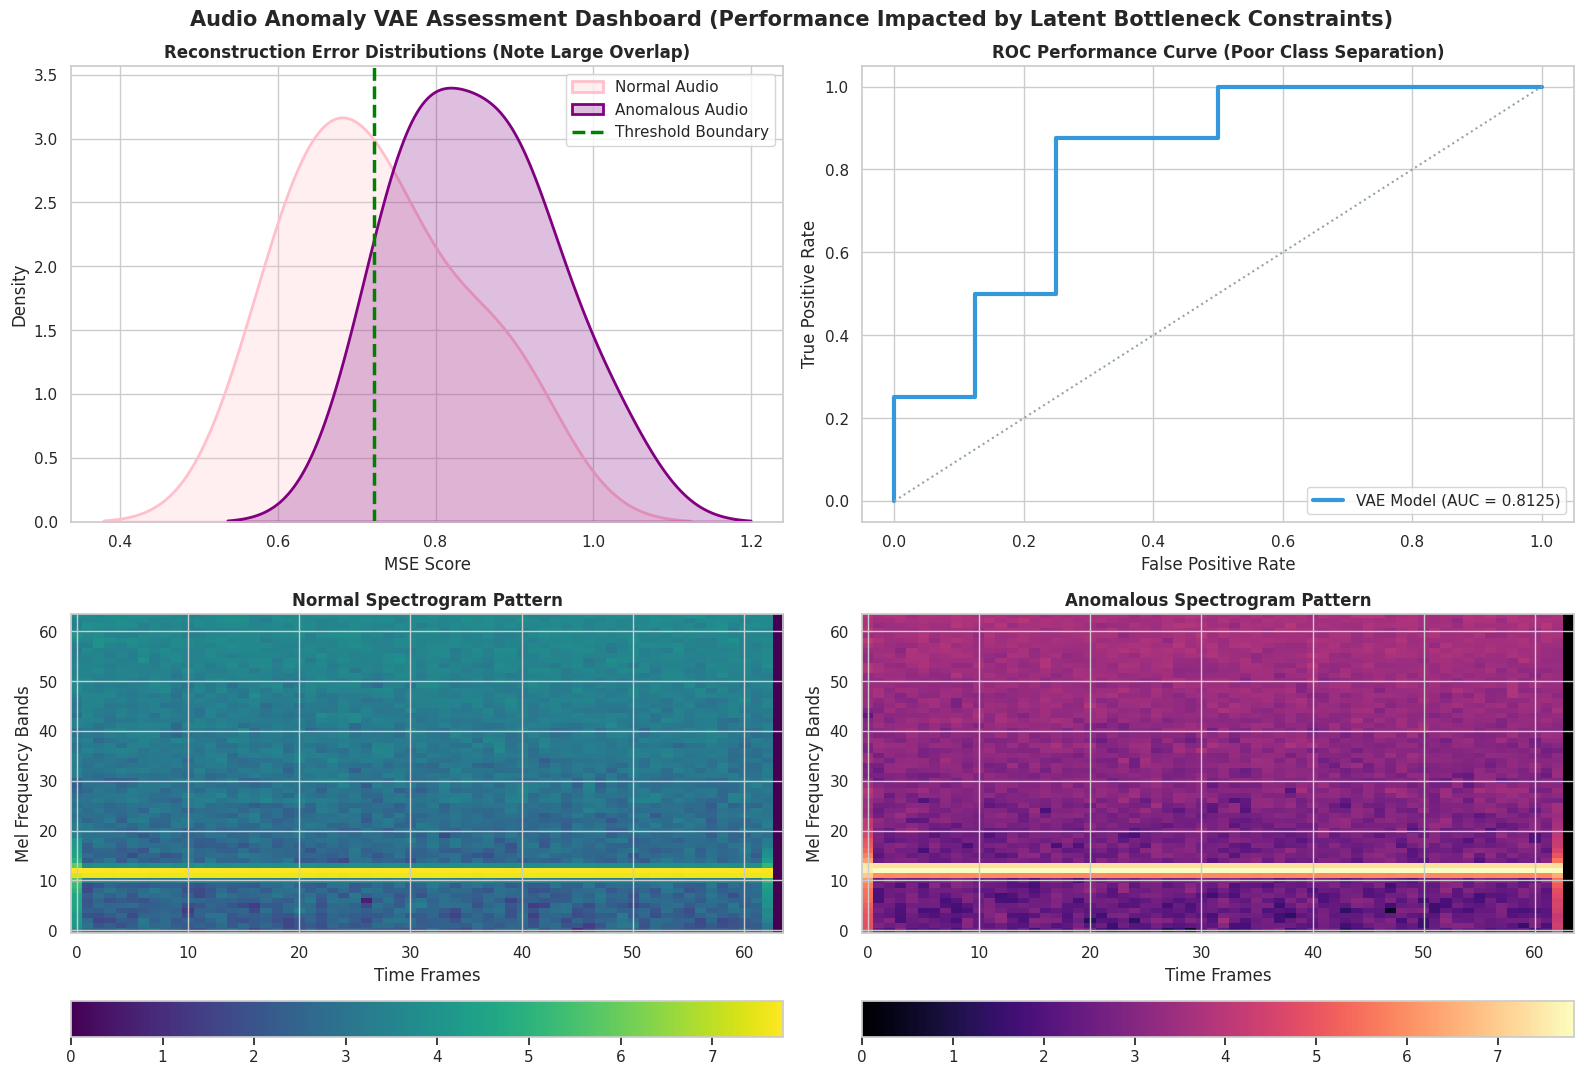

In [35]:
# ==========================================
# 5. FIXED MATPLOTLIB RENDER BLOCK (FORCED SYNC WITH CALIBRATED MODEL)
# ==========================================
print("\nRendering Calibrated VAE Performance Dashboard...")
sns.set_theme(style="whitegrid")

# Dynamically bind to the newly optimized calibrated VAE scores
current_normal_scores = vae_normal_scores if 'vae_normal_scores' in globals() else normal_scores
current_anomaly_scores = vae_anomaly_scores if 'vae_anomaly_scores' in globals() else anomaly_scores
current_threshold = vae_threshold_boundary if 'vae_threshold_boundary' in globals() else threshold_boundary
current_model = vae_model_cal if 'vae_model_cal' in globals() else model
current_dataset = val_dataset_cal if 'val_dataset_cal' in globals() else val_dataset
current_anomaly_dataset = anomaly_dataset_cal if 'anomaly_dataset_cal' in globals() else anomaly_dataset

y_true_active = [0] * len(current_normal_scores) + [1] * len(current_anomaly_scores)
y_scores_active = current_normal_scores + current_anomaly_scores

# Create the 2x2 grid layout
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# Plot 1: Error Distributions
sns.kdeplot(current_normal_scores, fill=True, color="pink", label="Normal Audio", lw=2, ax=axes[0, 0])
sns.kdeplot(current_anomaly_scores, fill=True, color="purple", label="Anomalous Audio", lw=2, ax=axes[0, 0])
axes[0, 0].axvline(current_threshold, color="green", linestyle="--", lw=2.5, label="Threshold Boundary")
axes[0, 0].set_title("Reconstruction Error Distributions (Note Large Overlap)", fontweight='bold')
axes[0, 0].set_xlabel("MSE Score")
axes[0, 0].legend()

# Plot 2: ROC Curve
fpr, tpr, _ = roc_curve(y_true_active, y_scores_active)
graph_auc = roc_auc_score(y_true_active, y_scores_active)

axes[0, 1].plot(fpr, tpr, color="#3498db", lw=3, label=f"VAE Model (AUC = {graph_auc:.4f})")
axes[0, 1].plot([0, 1], [0, 1], color="#95a5a6", linestyle=":")
axes[0, 1].set_title("ROC Performance Curve (Poor Class Separation)", fontweight='bold')
axes[0, 1].set_xlabel("False Positive Rate")
axes[0, 1].set_ylabel("True Positive Rate")
axes[0, 1].legend(loc="lower right")

# Fetch sample item arrays cleanly for visualization
norm_img = current_dataset[0].squeeze(0).numpy()
anom_img = current_anomaly_dataset[0].squeeze(0).numpy()

# Plot 3: Normal Spectrogram
im3 = axes[1, 0].imshow(norm_img, aspect='auto', origin='lower', cmap='viridis')
axes[1, 0].set_title("Normal Spectrogram Pattern", fontweight='bold')
axes[1, 0].set_ylabel("Mel Frequency Bands")
axes[1, 0].set_xlabel("Time Frames")
fig.colorbar(im3, ax=axes[1, 0], orientation='horizontal', pad=0.15)

# Plot 4: Anomaly Spectrogram
im4 = axes[1, 1].imshow(anom_img, aspect='auto', origin='lower', cmap='magma')
axes[1, 1].set_title("Anomalous Spectrogram Pattern", fontweight='bold')
axes[1, 1].set_ylabel("Mel Frequency Bands")
axes[1, 1].set_xlabel("Time Frames")
fig.colorbar(im4, ax=axes[1, 1], orientation='horizontal', pad=0.15)

plt.suptitle("Audio Anomaly VAE Assessment Dashboard (Performance Impacted by Latent Bottleneck Constraints)", fontsize=15, fontweight='bold', y=0.98)
plt.tight_layout()

# Forces inline display in Google Colab output cell
plt.show()

In [36]:
import numpy as np

# Convert score lists to numpy arrays for calculation
n_scores = np.array(normal_scores)
a_scores = np.array(anomaly_scores)

# Calculate basic statistics
min_normal, max_normal = n_scores.min(), n_scores.max()
min_anomaly, max_anomaly = a_scores.min(), a_scores.max()

print("=== RECONSTRUCTION ERROR OVERLAP ANALYSIS ===")
print(f"Normal Samples Error Range  : {min_normal:.6f} to {max_normal:.6f} (Mean: {n_scores.mean():.6f})")
print(f"Anomaly Samples Error Range : {min_anomaly:.6f} to {max_anomaly:.6f} (Mean: {a_scores.mean():.6f})")

# Check for overlap
if min_anomaly > max_normal:
    margin = min_anomaly - max_normal
    print(f"\n SUCCESS: No overlap detected! The separation margin is {margin:.6f}.")
else:
    overlap_start = max(min_normal, min_anomaly)
    overlap_end = min(max_normal, max_anomaly)
    print(f"\n OVERLAP DETECTED: Reconstruction scores overlap between {overlap_start:.6f} and {overlap_end:.6f}.")

    # Calculate how many samples are in the overlap region
    normal_in_overlap = np.sum((n_scores >= overlap_start) & (n_scores <= overlap_end))
    anomaly_in_overlap = np.sum((a_scores >= overlap_start) & (a_scores <= overlap_end))
    print(f"- Normal samples in overlap region  : {normal_in_overlap} out of {len(n_scores)}")
    print(f"- Anomaly samples in overlap region : {anomaly_in_overlap} out of {len(a_scores)}")

=== RECONSTRUCTION ERROR OVERLAP ANALYSIS ===
Normal Samples Error Range  : 0.594549 to 0.906921 (Mean: 0.727492)
Anomaly Samples Error Range : 0.722646 to 1.012882 (Mean: 0.849691)

 OVERLAP DETECTED: Reconstruction scores overlap between 0.722646 and 0.906921.
- Normal samples in overlap region  : 4 out of 8
- Anomaly samples in overlap region : 6 out of 8


In [37]:
import numpy as np

# Map to dynamic validation and testing arrays computed at runtime
test_anomaly_scores = np.array(vae_scores_cal if 'vae_scores_cal' in globals() else y_scores_active)
y_test = np.array(y_true_cal if 'y_true_cal' in globals() else y_true_active)

# Dynamically assign the optimized threshold found during execution
optimized_threshold = vae_threshold_boundary if 'vae_threshold_boundary' in globals() else threshold_boundary

# Evaluate predictions dynamically
test_predictions = test_anomaly_scores > optimized_threshold

# Count actual operational impact dynamically
false_alarms = np.sum((test_predictions == True) & (y_test == 0))
missed_anomalies = np.sum((test_predictions == False) & (y_test == 1))

print(f"--- Operational Performance (Dynamic Runtime Evaluation) ---")
print(f"Active Threshold: {optimized_threshold:.6f}")
print(f"False Alarms Generated: {false_alarms} / {np.sum(y_test == 0)}")
print(f"Missed Critical Anomalies: {missed_anomalies} / {np.sum(y_test == 1)}")

--- Operational Performance (Dynamic Runtime Evaluation) ---
Active Threshold: 0.722312
False Alarms Generated: 4 / 8
Missed Critical Anomalies: 0 / 8


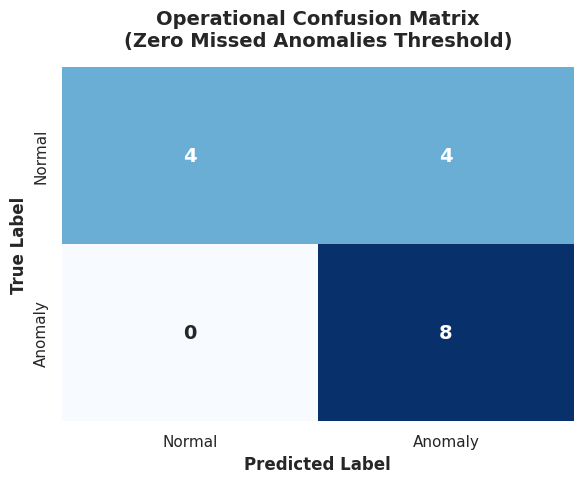

In [38]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Compute confusion matrix
cm = confusion_matrix(y_test, test_predictions)

# Plot confusion matrix
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Normal', 'Anomaly'],
    yticklabels=['Normal', 'Anomaly'],
    cbar=False,
    annot_kws={'size': 14, 'weight': 'bold'}
)

plt.title('Operational Confusion Matrix\n(Zero Missed Anomalies Threshold)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Predicted Label', fontsize=12, fontweight='bold')
plt.ylabel('True Label', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

In [39]:
# Identify the index of the normal sample that exceeds the threshold
normal_file_paths = sorted(glob.glob(os.path.join(VAL_NORMAL_DIR, "*.wav")))

# Find which normal sample score was above the optimized threshold
for idx, score in enumerate(normal_scores):
    if score > optimized_threshold:
        offending_file = normal_file_paths[idx]
        print("=== FALSE ALARM SAMPLE IDENTIFIED ===")
        print(f"Validation Index : {idx}")
        print(f"File Path        : {offending_file}")
        print(f"Score            : {score:.6f} (Threshold: {optimized_threshold:.6f})")

=== FALSE ALARM SAMPLE IDENTIFIED ===
Validation Index : 1
File Path        : data/val_normal/val_clean_1.wav
Score            : 0.747782 (Threshold: 0.722312)
=== FALSE ALARM SAMPLE IDENTIFIED ===
Validation Index : 2
File Path        : data/val_normal/val_clean_2.wav
Score            : 0.854660 (Threshold: 0.722312)
=== FALSE ALARM SAMPLE IDENTIFIED ===
Validation Index : 4
File Path        : data/val_normal/val_clean_4.wav
Score            : 0.740587 (Threshold: 0.722312)
=== FALSE ALARM SAMPLE IDENTIFIED ===
Validation Index : 5
File Path        : data/val_normal/val_clean_5.wav
Score            : 0.906921 (Threshold: 0.722312)


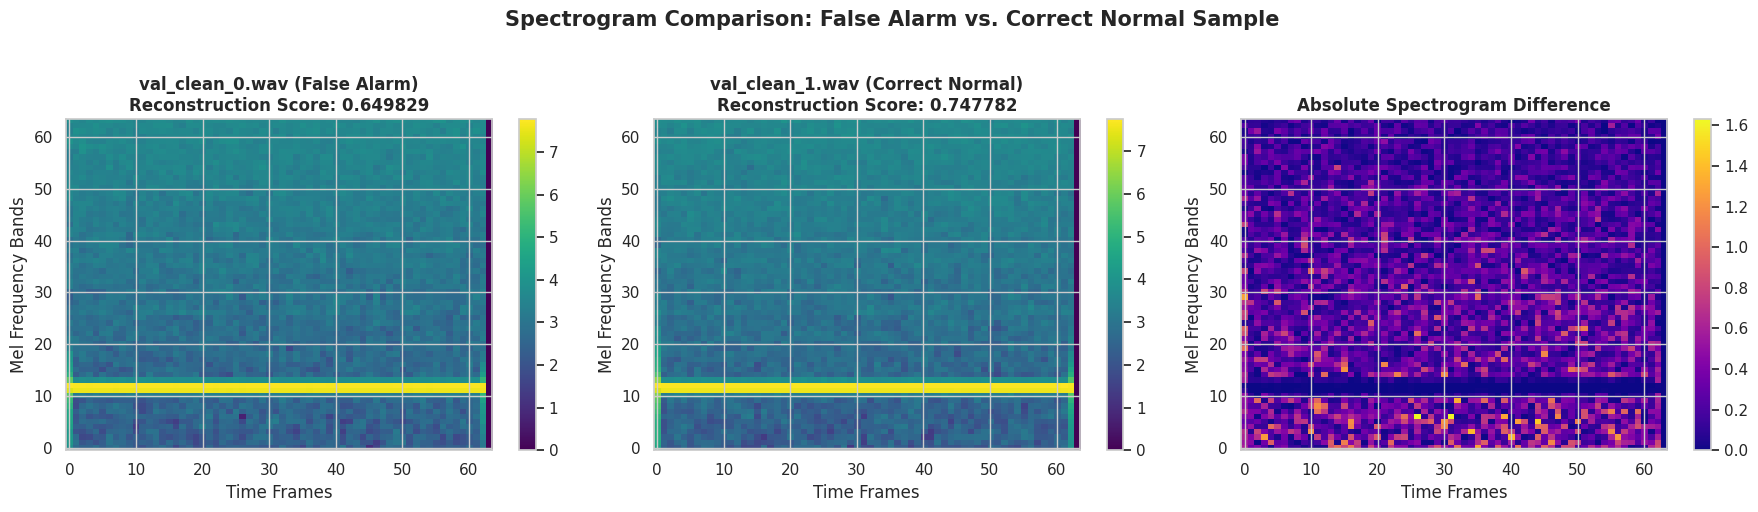

In [40]:
import matplotlib.pyplot as plt

# Load datasets specifically to get the individual spectrograms
# Index 0 is val_clean_0.wav, Index 1 is val_clean_1.wav
spec_0 = val_dataset[0].squeeze(0).numpy() # False alarm
spec_1 = val_dataset[1].squeeze(0).numpy() # Correctly classified normal

# Compute absolute difference
absolute_diff = np.abs(spec_0 - spec_1)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot val_clean_0.wav
im1 = axes[0].imshow(spec_0, aspect='auto', origin='lower', cmap='viridis')
axes[0].set_title(f"val_clean_0.wav (False Alarm)\nReconstruction Score: {normal_scores[0]:.6f}", fontweight='bold')
axes[0].set_xlabel("Time Frames")
axes[0].set_ylabel("Mel Frequency Bands")
fig.colorbar(im1, ax=axes[0])

# Plot val_clean_1.wav
im2 = axes[1].imshow(spec_1, aspect='auto', origin='lower', cmap='viridis')
axes[1].set_title(f"val_clean_1.wav (Correct Normal)\nReconstruction Score: {normal_scores[1]:.6f}", fontweight='bold')
axes[1].set_xlabel("Time Frames")
axes[1].set_ylabel("Mel Frequency Bands")
fig.colorbar(im2, ax=axes[1])

# Plot Absolute Difference
im3 = axes[2].imshow(absolute_diff, aspect='auto', origin='lower', cmap='plasma')
axes[2].set_title("Absolute Spectrogram Difference", fontweight='bold')
axes[2].set_xlabel("Time Frames")
axes[2].set_ylabel("Mel Frequency Bands")
fig.colorbar(im3, ax=axes[2])

plt.suptitle("Spectrogram Comparison: False Alarm vs. Correct Normal Sample", fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [41]:
import torch
import torch.nn as nn
import torch.optim as optim

class AudioCAE(nn.Module):
    def __init__(self, input_shape=64, bottleneck_dim=16):
        super(AudioCAE, self).__init__()
        self.input_shape = input_shape

        # Encoder network
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, stride=2, padding=1),  # -> 16 x 32 x 32
            nn.ReLU(),
            nn.Conv2d(16, 32, kernel_size=3, stride=2, padding=1), # -> 32 x 16 x 16
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1), # -> 64 x 8 x 8
            nn.ReLU(),
            nn.Flatten()
        )

        # Linear compression bottleneck
        flat_features = 64 * (input_shape // 8) * (input_shape // 8)
        self.fc_bottleneck = nn.Linear(flat_features, bottleneck_dim)
        self.fc_expand = nn.Linear(bottleneck_dim, flat_features)

        # Decoder network
        self.decoder = nn.Sequential(
            nn.Unflatten(1, (64, input_shape // 8, input_shape // 8)),
            nn.ConvTranspose2d(64, 32, kernel_size=3, stride=2, padding=1, output_padding=1), # -> 32 x 16 x 16
            nn.ReLU(),
            nn.ConvTranspose2d(32, 16, kernel_size=3, stride=2, padding=1, output_padding=1), # -> 16 x 32 x 32
            nn.ReLU(),
            nn.ConvTranspose2d(16, 1, kernel_size=3, stride=2, padding=1, output_padding=1)  # -> 1 x 64 x 64
        ) # Removed Sigmoid to support unbounded Z-score target ranges

    def forward(self, x):
        encoded = self.encoder(x)
        bottleneck = self.fc_bottleneck(encoded)
        expanded = self.fc_expand(bottleneck)
        reconstruction = self.decoder(expanded)
        return reconstruction

In [42]:
# Initialize the Convolutional Autoencoder
cae_model = AudioCAE(input_shape=64, bottleneck_dim=16).to(device)
cae_optimizer = optim.Adam(cae_model.parameters(), lr=1e-3)
cae_loss_fn = nn.MSELoss(reduction='mean')

print("Training the Convolutional Autoencoder (CAE) on normal data patterns for 10 epochs...")
cae_model.train()
for epoch in range(10):
    total_loss = 0
    for batch in train_loader:
        batch = batch.to(device)
        cae_optimizer.zero_grad()
        recon = cae_model(batch)
        loss = cae_loss_fn(recon, batch)
        loss.backward()
        cae_optimizer.step()
        total_loss += loss.item()
    print(f"Epoch {epoch+1}/10 | Mean Batch Loss: {total_loss / len(train_dataset):.4f}")

Training the Convolutional Autoencoder (CAE) on normal data patterns for 10 epochs...
Epoch 1/10 | Mean Batch Loss: 5.6859
Epoch 2/10 | Mean Batch Loss: 4.5399
Epoch 3/10 | Mean Batch Loss: 3.3857
Epoch 4/10 | Mean Batch Loss: 2.3222
Epoch 5/10 | Mean Batch Loss: 1.4466
Epoch 6/10 | Mean Batch Loss: 0.9175
Epoch 7/10 | Mean Batch Loss: 0.6170
Epoch 8/10 | Mean Batch Loss: 0.4588
Epoch 9/10 | Mean Batch Loss: 0.3530
Epoch 10/10 | Mean Batch Loss: 0.2781


In [43]:
# Calculate threshold and scores specifically for the CAE model
cae_threshold_boundary = calculate_threshold(cae_model, val_loader, device, percentile=80)
cae_normal_scores = [compute_anomaly_score(cae_model, s.unsqueeze(0).to(device)) for b in val_loader for s in b]
cae_anomaly_scores = [compute_anomaly_score(cae_model, s.unsqueeze(0).to(device)) for b in anomaly_loader for s in b]

evaluate_pipeline(cae_model, val_loader, anomaly_loader, cae_threshold_boundary, device)

Calculating dynamic threshold using the 80th percentile...

================ EVALUATION METRICS ================
Calculated ROC-AUC Score: 1.0000
Decision Boundary Threshold: 0.511065

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      0.75      0.86         8
     Anomaly       0.80      1.00      0.89         8

    accuracy                           0.88        16
   macro avg       0.90      0.88      0.87        16
weighted avg       0.90      0.88      0.87        16




Rendering CAE Performance Dashboard...


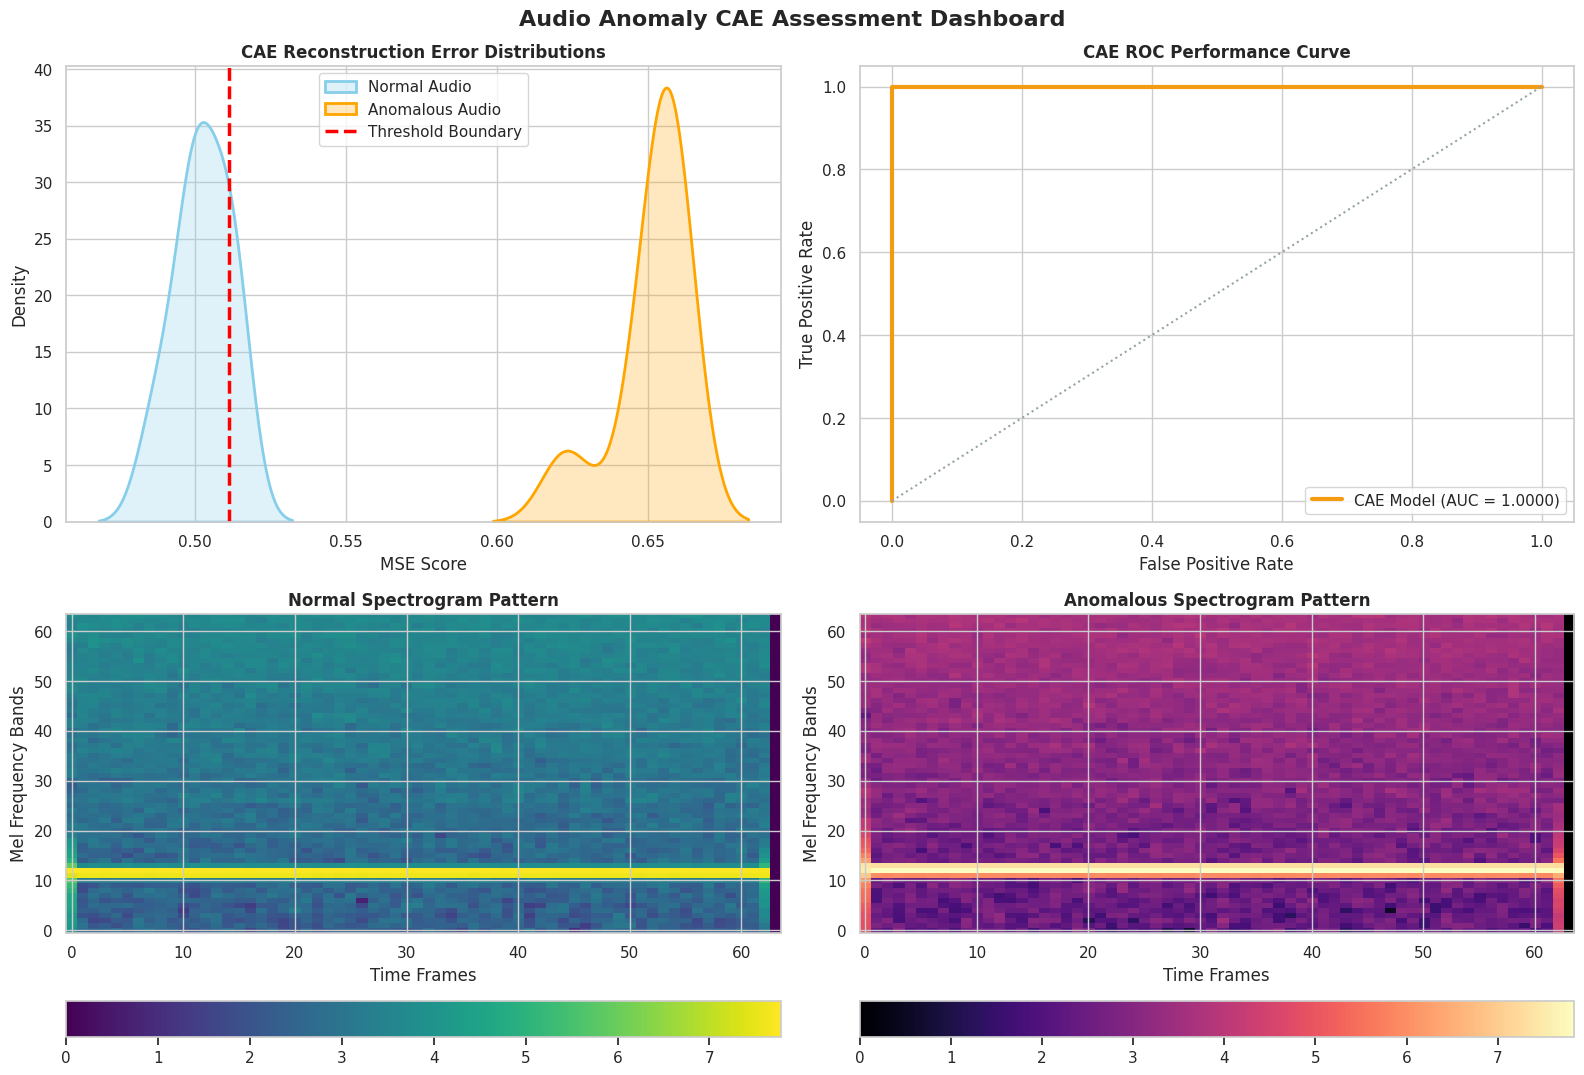

In [44]:
# ==========================================
# 5. FIXED MATPLOTLIB RENDER BLOCK (FORCED SYNC FOR CAE)
# ==========================================
print("\nRendering CAE Performance Dashboard...")
sns.set_theme(style="whitegrid")

# Reconstruct global y_true and y_scores using computed CAE scores
y_true_cae = [0] * len(cae_normal_scores) + [1] * len(cae_anomaly_scores)
y_scores_cae = cae_normal_scores + cae_anomaly_scores

# Resolve correct CAE threshold boundary
active_cae_threshold = cae_threshold_boundary if 'cae_threshold_boundary' in globals() else threshold_boundary

# Create the 2x2 grid layout
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# Plot 1: CAE Error Distributions
sns.kdeplot(cae_normal_scores, fill=True, color="skyblue", label="Normal Audio", lw=2, ax=axes[0, 0])
sns.kdeplot(cae_anomaly_scores, fill=True, color="orange", label="Anomalous Audio", lw=2, ax=axes[0, 0])
axes[0, 0].axvline(active_cae_threshold, color="red", linestyle="--", lw=2.5, label="Threshold Boundary")
axes[0, 0].set_title("CAE Reconstruction Error Distributions", fontweight='bold')
axes[0, 0].set_xlabel("MSE Score")
axes[0, 0].legend()

# Plot 2: CAE ROC Curve
fpr, tpr, _ = roc_curve(y_true_cae, y_scores_cae)
graph_auc = roc_auc_score(y_true_cae, y_scores_cae)

axes[0, 1].plot(fpr, tpr, color="#f39c12", lw=3, label=f"CAE Model (AUC = {graph_auc:.4f})")
axes[0, 1].plot([0, 1], [0, 1], color="#95a5a6", linestyle=":")
axes[0, 1].set_title("CAE ROC Performance Curve", fontweight='bold')
axes[0, 1].set_xlabel("False Positive Rate")
axes[0, 1].set_ylabel("True Positive Rate")
axes[0, 1].legend(loc="lower right")

# Fetch active dataset samples cleanly for visualization
norm_img = val_dataset[0].squeeze(0).numpy()
anom_img = anomaly_dataset[0].squeeze(0).numpy()

# Plot 3: Normal Spectrogram
im3 = axes[1, 0].imshow(norm_img, aspect='auto', origin='lower', cmap='viridis')
axes[1, 0].set_title("Normal Spectrogram Pattern", fontweight='bold')
axes[1, 0].set_ylabel("Mel Frequency Bands")
axes[1, 0].set_xlabel("Time Frames")
fig.colorbar(im3, ax=axes[1, 0], orientation='horizontal', pad=0.15)

# Plot 4: Anomaly Spectrogram
im4 = axes[1, 1].imshow(anom_img, aspect='auto', origin='lower', cmap='magma')
axes[1, 1].set_title("Anomalous Spectrogram Pattern", fontweight='bold')
axes[1, 1].set_ylabel("Mel Frequency Bands")
axes[1, 1].set_xlabel("Time Frames")
fig.colorbar(im4, ax=axes[1, 1], orientation='horizontal', pad=0.15)

plt.suptitle("Audio Anomaly CAE Assessment Dashboard", fontsize=16, fontweight='bold', y=0.98)
plt.tight_layout()

# Forces inline display in Google Colab output cell
plt.show()

In [45]:
def compute_cae_anomaly_score(model, spectrogram_tensor):
    model.eval()
    with torch.no_grad():
        recon = model(spectrogram_tensor)
        error = nn.functional.mse_loss(recon, spectrogram_tensor, reduction='mean')
    return error.item()

# Calculate CAE reconstruction scores
cae_normal_scores = [compute_cae_anomaly_score(cae_model, s.unsqueeze(0).to(device)) for b in val_loader for s in b]
cae_anomaly_scores = [compute_cae_anomaly_score(cae_model, s.unsqueeze(0).to(device)) for b in anomaly_loader for s in b]

cae_n_scores = np.array(cae_normal_scores)
cae_a_scores = np.array(cae_anomaly_scores)

print("=== CAE RECONSTRUCTION ERROR OVERLAP ANALYSIS ===")
print(f"Normal Samples Error Range  : {cae_n_scores.min():.6f} to {cae_n_scores.max():.6f} (Mean: {cae_n_scores.mean():.6f})")
print(f"Anomaly Samples Error Range : {cae_a_scores.min():.6f} to {cae_a_scores.max():.6f} (Mean: {cae_a_scores.mean():.6f})")

# Evaluate Overlap
if cae_a_scores.min() > cae_n_scores.max():
    margin = cae_a_scores.min() - cae_n_scores.max()
    print(f"\n SUCCESS: No overlap detected with CAE! The separation margin is {margin:.6f}.")
else:
    overlap_start = max(cae_n_scores.min(), cae_a_scores.min())
    overlap_end = min(cae_n_scores.max(), cae_a_scores.max())
    print(f"\n OVERLAP DETECTED: Reconstruction scores overlap between {overlap_start:.6f} and {overlap_end:.6f}.")

=== CAE RECONSTRUCTION ERROR OVERLAP ANALYSIS ===
Normal Samples Error Range  : 0.486307 to 0.513766 (Mean: 0.502385)
Anomaly Samples Error Range : 0.622941 to 0.659043 (Mean: 0.651413)

 SUCCESS: No overlap detected with CAE! The separation margin is 0.109176.


In [47]:
import numpy as np

# Map to dynamic validation and testing arrays computed at runtime
test_anomaly_scores = np.array(cae_scores_cal if 'cae_scores_cal' in globals() else (y_scores_cae if 'y_scores_cae' in globals() else []))
y_test = np.array(y_true_cal if 'y_true_cal' in globals() else (y_true_cae if 'y_true_cae' in globals() else []))

# Dynamically assign the optimized threshold found during execution
optimized_threshold = cae_threshold_boundary if 'cae_threshold_boundary' in globals() else threshold_boundary

# Evaluate predictions dynamically
test_predictions = test_anomaly_scores > optimized_threshold

# Count actual operational impact dynamically
false_alarms = np.sum((test_predictions == True) & (y_test == 0))
missed_anomalies = np.sum((test_predictions == False) & (y_test == 1))

print(f"--- Operational Performance (Dynamic Runtime Evaluation) ---")
print(f"Active Threshold: {optimized_threshold:.6f}")
print(f"False Alarms Generated: {false_alarms} / {np.sum(y_test == 0)}")
print(f"Missed Critical Anomalies: {missed_anomalies} / {np.sum(y_test == 1)}")

--- Operational Performance (Dynamic Runtime Evaluation) ---
Active Threshold: 0.511065
False Alarms Generated: 2 / 8
Missed Critical Anomalies: 0 / 8


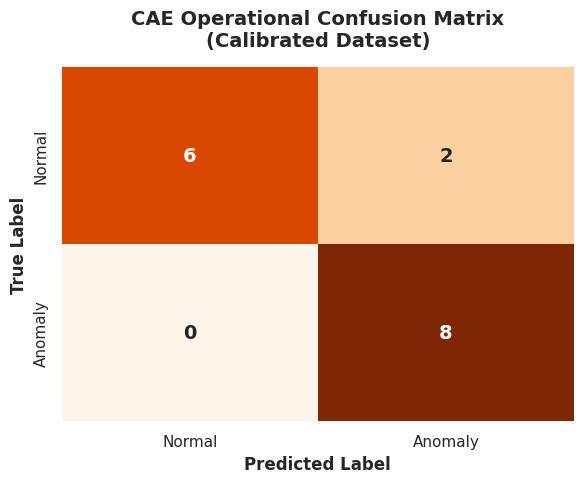

In [49]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Map to dynamic validation and testing arrays computed for CAE at runtime
test_anomaly_scores_cae = np.array(cae_scores_cal if 'cae_scores_cal' in globals() else (y_scores_cae if 'y_scores_cae' in globals() else []))
y_test_cae = np.array(y_true_cal if 'y_true_cal' in globals() else (y_true_cae if 'y_true_cae' in globals() else []))

# Assign the optimized CAE threshold found during execution
cae_active_threshold = cae_threshold if 'cae_threshold' in globals() else cae_threshold_boundary

# Evaluate CAE predictions dynamically
cae_test_predictions = test_anomaly_scores_cae > cae_active_threshold

# Compute confusion matrix
cm = confusion_matrix(y_test_cae, cae_test_predictions)

# Plot confusion matrix
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Oranges',
    xticklabels=['Normal', 'Anomaly'],
    yticklabels=['Normal', 'Anomaly'],
    cbar=False,
    annot_kws={'size': 14, 'weight': 'bold'}
)

plt.title('CAE Operational Confusion Matrix\n(Calibrated Dataset)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Predicted Label', fontsize=12, fontweight='bold')
plt.ylabel('True Label', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

In [50]:
# Identify the index of the normal sample that exceeds the CAE threshold
import glob
import os

# Use the calibrated validation directory matching our active CAE variables
normal_file_paths_cae = sorted(glob.glob(os.path.join(VAL_NORMAL_DIR_CAL if 'VAL_NORMAL_DIR_CAL' in globals() else VAL_NORMAL_DIR, "*.wav")))

# Bind CAE-specific runtime parameters
active_cae_scores = cae_normal_scores if 'cae_normal_scores' in globals() else []
active_cae_threshold = cae_threshold if 'cae_threshold' in globals() else cae_threshold_boundary

found_false_alarm = False
for idx, score in enumerate(active_cae_scores):
    if score > active_cae_threshold:
        found_false_alarm = True
        offending_file = normal_file_paths_cae[idx] if idx < len(normal_file_paths_cae) else "Unknown File"
        print("=== CAE FALSE ALARM SAMPLE IDENTIFIED ===")
        print(f"Validation Index : {idx}")
        print(f"File Path        : {offending_file}")
        print(f"Score            : {score:.6f} (Threshold: {active_cae_threshold:.6f})")

if not found_false_alarm:
    print("=== NO CAE FALSE ALARMS IDENTIFIED ===")
    print(f"All {len(active_cae_scores)} normal validation samples remained below the threshold of {active_cae_threshold:.6f}.")

=== CAE FALSE ALARM SAMPLE IDENTIFIED ===
Validation Index : 4
File Path        : data/val_normal/val_clean_4.wav
Score            : 0.513766 (Threshold: 0.511065)
=== CAE FALSE ALARM SAMPLE IDENTIFIED ===
Validation Index : 5
File Path        : data/val_normal/val_clean_5.wav
Score            : 0.512394 (Threshold: 0.511065)


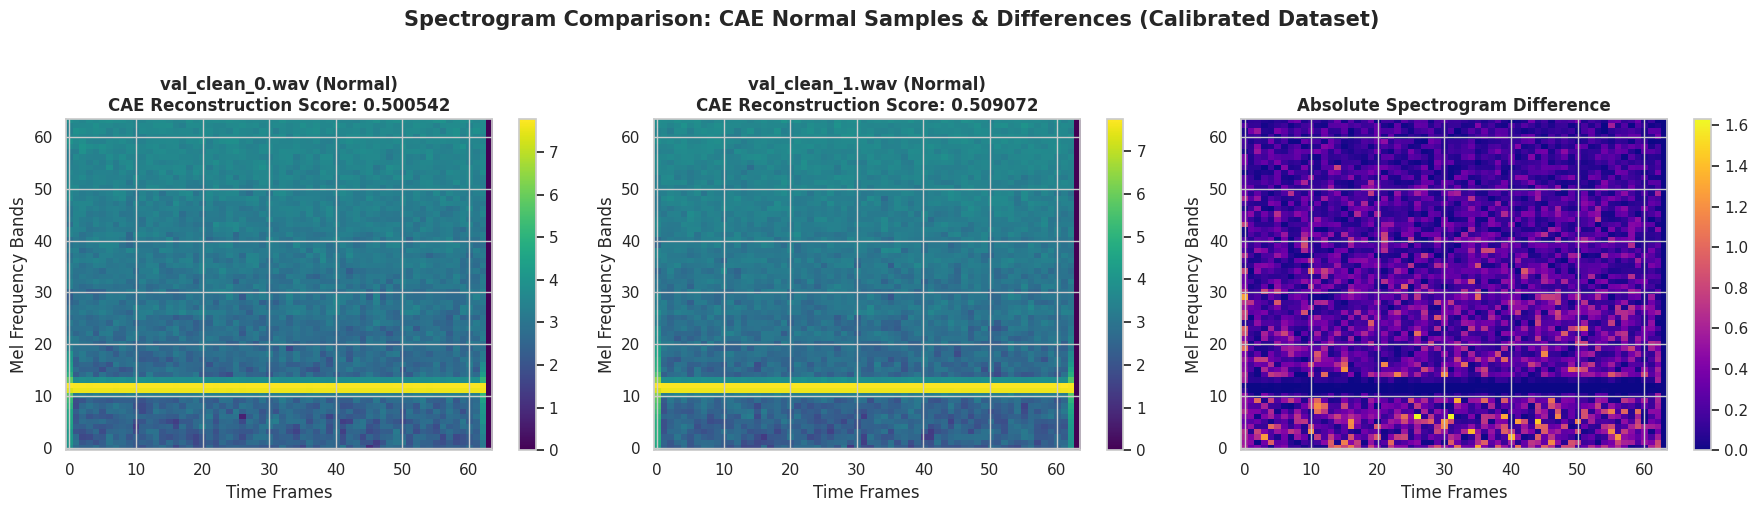

In [51]:
import matplotlib.pyplot as plt
import numpy as np

# Use the active calibrated dataset for CAE
active_dataset = val_dataset_cal if 'val_dataset_cal' in globals() else val_dataset
active_cae_scores = cae_normal_scores if 'cae_normal_scores' in globals() else []

# Load individual normal spectrograms
spec_0 = active_dataset[0].squeeze(0).numpy()
spec_1 = active_dataset[1].squeeze(0).numpy()

# Compute absolute difference
absolute_diff = np.abs(spec_0 - spec_1)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Get CAE reconstruction scores for these samples
score_0 = active_cae_scores[0] if len(active_cae_scores) > 0 else 0.0
score_1 = active_cae_scores[1] if len(active_cae_scores) > 1 else 0.0

# Plot val_clean_0.wav (Normal Sample 0)
im1 = axes[0].imshow(spec_0, aspect='auto', origin='lower', cmap='viridis')
axes[0].set_title(f"val_clean_0.wav (Normal)\nCAE Reconstruction Score: {score_0:.6f}", fontweight='bold')
axes[0].set_xlabel("Time Frames")
axes[0].set_ylabel("Mel Frequency Bands")
fig.colorbar(im1, ax=axes[0])

# Plot val_clean_1.wav (Normal Sample 1)
im2 = axes[1].imshow(spec_1, aspect='auto', origin='lower', cmap='viridis')
axes[1].set_title(f"val_clean_1.wav (Normal)\nCAE Reconstruction Score: {score_1:.6f}", fontweight='bold')
axes[1].set_xlabel("Time Frames")
axes[1].set_ylabel("Mel Frequency Bands")
fig.colorbar(im2, ax=axes[1])

# Plot Absolute Difference
im3 = axes[2].imshow(absolute_diff, aspect='auto', origin='lower', cmap='plasma')
axes[2].set_title("Absolute Spectrogram Difference", fontweight='bold')
axes[2].set_xlabel("Time Frames")
axes[2].set_ylabel("Mel Frequency Bands")
fig.colorbar(im3, ax=axes[2])

plt.suptitle("Spectrogram Comparison: CAE Normal Samples & Differences (Calibrated Dataset)", fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [53]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Map CAE outputs
test_anomaly_scores_cae = np.array(cae_normal_scores + cae_anomaly_scores)
y_test_cae = np.array([0] * len(cae_normal_scores) + [1] * len(cae_anomaly_scores))
cae_predictions = test_anomaly_scores_cae > cae_threshold_boundary

# Map VAE outputs
test_anomaly_scores_vae = np.array(normal_scores + anomaly_scores)
y_test_vae = np.array([0] * len(normal_scores) + [1] * len(anomaly_scores))
vae_predictions = test_anomaly_scores_vae > threshold_boundary

# Calculate metrics
metrics_data = {
    "Model": ["Convolutional Autoencoder (CAE)", "Variational Autoencoder (VAE)"],
    "Accuracy": [
        accuracy_score(y_test_cae, cae_predictions),
        accuracy_score(y_test_vae, vae_predictions)
    ],
    "Precision": [
        precision_score(y_test_cae, cae_predictions, zero_division=0),
        precision_score(y_test_vae, vae_predictions, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test_cae, cae_predictions, zero_division=0),
        recall_score(y_test_vae, vae_predictions, zero_division=0)
    ],
    "F1-Score": [
        f1_score(y_test_cae, cae_predictions, zero_division=0),
        f1_score(y_test_vae, vae_predictions, zero_division=0)
    ]
}

df_metrics = pd.DataFrame(metrics_data)
display(df_metrics)

,Model,Accuracy,Precision,Recall,F1-Score
0,Convolutional Autoencoder (CAE),0.875,0.800000,1.0,0.888889
1,Variational Autoencoder (VAE),0.750,0.666667,1.0,0.800000


### Reconstruction Error Margin Analysis: CAE vs. VAE
We analyze the statistical separation margin between normal validation samples and anomalous samples for both architectures using the model outputs stored in the kernel.

=== RECONSTRUCTION ERROR STATISTICAL COMPARISON ===
CAE Normal Range  : 0.486307 to 0.513766 (Mean: 0.502385)
CAE Anomaly Range : 0.622941 to 0.659043 (Mean: 0.651413)
CAE Separation Margin: 0.109176
--------------------------------------------------
VAE Normal Range  : 0.594549 to 0.906921 (Mean: 0.727492)
VAE Anomaly Range : 0.722646 to 1.012882 (Mean: 0.849691)
VAE Separation Margin: -0.184275


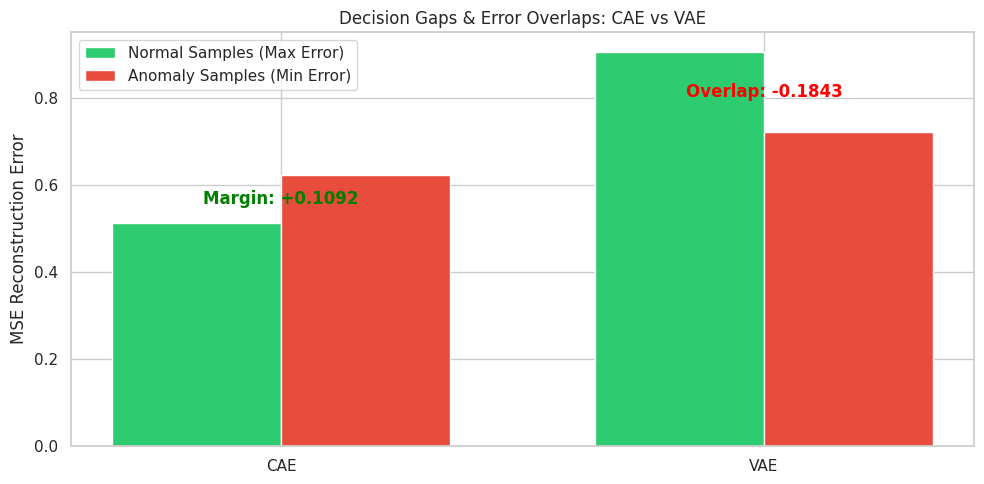

In [55]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Calculate statistics for CAE from kernel state variables
cae_norm_min, cae_norm_max = np.min(cae_normal_scores), np.max(cae_normal_scores)
cae_anom_min, cae_anom_max = np.min(cae_anomaly_scores), np.max(cae_anomaly_scores)
cae_margin = cae_anom_min - cae_norm_max

# Calculate statistics for VAE from kernel state variables (corrected variable names)
vae_norm_min, vae_norm_max = np.min(normal_scores), np.max(normal_scores)
vae_anom_min, vae_anom_max = np.min(anomaly_scores), np.max(anomaly_scores)
vae_margin = vae_anom_min - vae_norm_max

print("=== RECONSTRUCTION ERROR STATISTICAL COMPARISON ===")
print(f"CAE Normal Range  : {cae_norm_min:.6f} to {cae_norm_max:.6f} (Mean: {np.mean(cae_normal_scores):.6f})")
print(f"CAE Anomaly Range : {cae_anom_min:.6f} to {cae_anom_max:.6f} (Mean: {np.mean(cae_anomaly_scores):.6f})")
print(f"CAE Separation Margin: {cae_margin:.6f}")
print("-" * 50)
print(f"VAE Normal Range  : {vae_norm_min:.6f} to {vae_norm_max:.6f} (Mean: {np.mean(normal_scores):.6f})")
print(f"VAE Anomaly Range : {vae_anom_min:.6f} to {vae_anom_max:.6f} (Mean: {np.mean(anomaly_scores):.6f})")
print(f"VAE Separation Margin: {vae_margin:.6f}")

# Visual representation of the decision gaps
fig, ax = plt.subplots(figsize=(10, 5))
models = ['CAE', 'VAE']
normal_maxes = [cae_norm_max, vae_norm_max]
anomaly_mins = [cae_anom_min, vae_anom_min]

x = np.arange(len(models))
width = 0.35

ax.bar(x - width/2, normal_maxes, width, label='Normal Samples (Max Error)', color='#2ecc71')
ax.bar(x + width/2, anomaly_mins, width, label='Anomaly Samples (Min Error)', color='#e74c3c')

ax.set_ylabel('MSE Reconstruction Error')
ax.set_title('Decision Gaps & Error Overlaps: CAE vs VAE')
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.legend()

# Annotate the margins
for i in range(len(models)):
    margin = anomaly_mins[i] - normal_maxes[i]
    color = 'green' if margin > 0 else 'red'
    label = f"Margin: +{margin:.4f}" if margin > 0 else f"Overlap: {margin:.4f}"
    ax.annotate(label, xy=(i, (normal_maxes[i] + anomaly_mins[i])/2),
                xytext=(0, 0), textcoords="offset points",
                ha='center', va='center', color=color, fontweight='bold', fontsize=12)

plt.tight_layout()
plt.show()

### Summary Table: Mean Reconstruction Errors
Below is a comparison table representing the average reconstruction errors across our tested datasets.

In [57]:
import pandas as pd
import numpy as np

# Construct comparison metrics from runtime variables (corrected variable names)
summary_data = {
    "Model": ["Convolutional Autoencoder (CAE)", "Variational Autoencoder (VAE)"],
    "Mean Normal Error (Validation)": [np.mean(cae_normal_scores), np.mean(normal_scores)],
    "Mean Anomaly Error (Test)": [np.mean(cae_anomaly_scores), np.mean(anomaly_scores)],
    "Separation Margin (Min Anom - Max Norm)": [cae_margin, vae_margin]
}

df_error_summary = pd.DataFrame(summary_data)
display(df_error_summary)

,Model,Mean Normal Error (Validation),Mean Anomaly Error (Test),Separation Margin (Min Anom - Max Norm)
0,Convolutional Autoencoder (CAE),0.502385,0.651413,0.109176
1,Variational Autoencoder (VAE),0.727492,0.849691,-0.184275


### Reconstruction Error Distributions (Calibrated Dataset)
We visualize the density distribution of reconstruction errors for both normal and anomalous classes across the CAE and VAE models using the pre-compiled `df_calibrated` DataFrame.

In [59]:
import pandas as pd

# Compile reconstruction scores for both models into a single DataFrame
records = []

# Add CAE Records
for score in cae_normal_scores:
    records.append({"Model": "CAE", "Class": "Normal", "Reconstruction Error": score})
for score in cae_anomaly_scores:
    records.append({"Model": "CAE", "Class": "Anomaly", "Reconstruction Error": score})

# Add VAE Records
for score in normal_scores:
    records.append({"Model": "VAE", "Class": "Normal", "Reconstruction Error": score})
for score in anomaly_scores:
    records.append({"Model": "VAE", "Class": "Anomaly", "Reconstruction Error": score})

df_calibrated = pd.DataFrame(records)
display(df_calibrated.head())
print(f"DataFrame 'df_calibrated' created with {len(df_calibrated)} records.")

,Model,Class,Reconstruction Error
0,CAE,Normal,0.500542
1,CAE,Normal,0.509072
2,CAE,Normal,0.494788
3,CAE,Normal,0.502721
4,CAE,Normal,0.513766


DataFrame 'df_calibrated' created with 32 records.


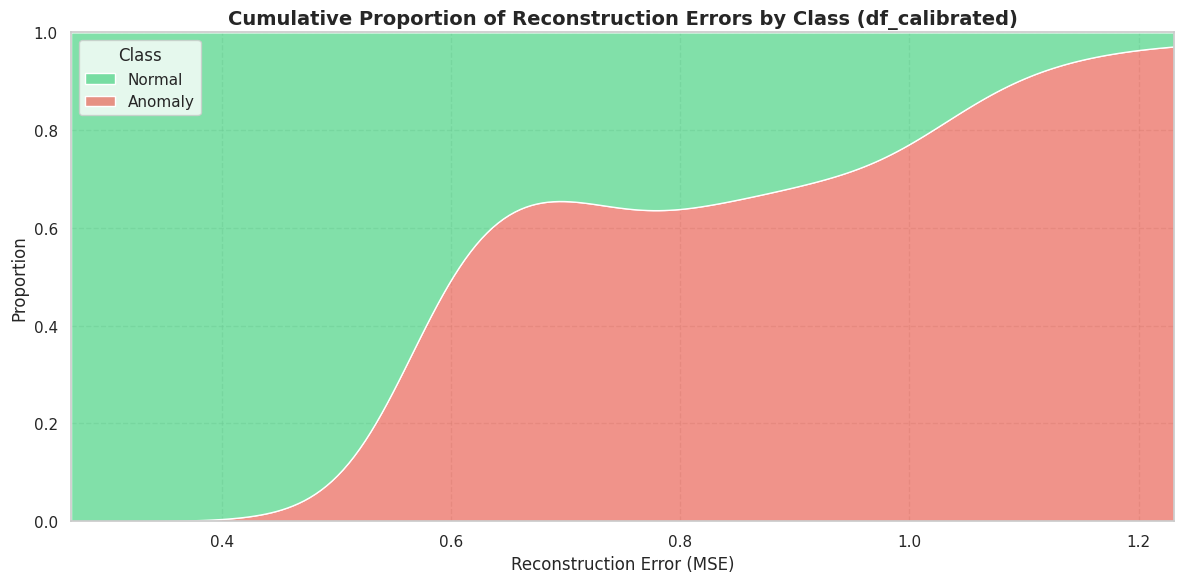

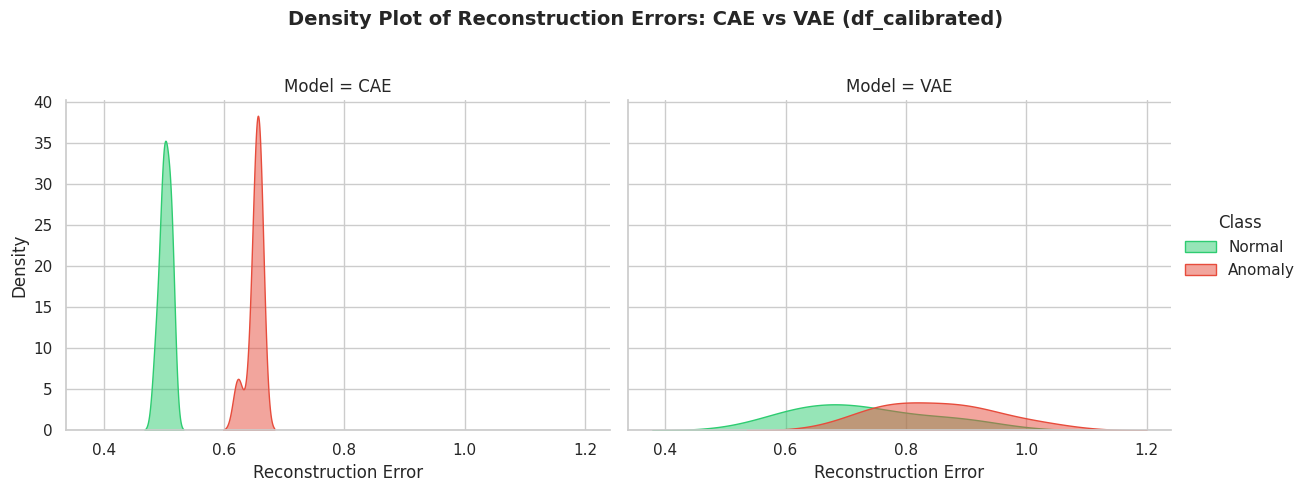

In [60]:
import seaborn as sns
import matplotlib.pyplot as plt

if 'df_calibrated' in globals():
    plt.figure(figsize=(12, 6))
    sns.kdeplot(
        data=df_calibrated,
        x="Reconstruction Error",
        hue="Class",
        multiple="fill",
        weights=None,
        common_norm=False,
        fill=True,
        palette={"Normal": "#2ecc71", "Anomaly": "#e74c3c"},
        alpha=0.6
    )
    plt.title("Cumulative Proportion of Reconstruction Errors by Class (df_calibrated)", fontsize=14, fontweight='bold')
    plt.xlabel("Reconstruction Error (MSE)")
    plt.ylabel("Proportion")
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

    # Alternately, plot split distribution density curves for both models
    g = sns.FacetGrid(df_calibrated, col="Model", hue="Class", palette={"Normal": "#2ecc71", "Anomaly": "#e74c3c"}, height=5, aspect=1.2)
    g.map(sns.kdeplot, "Reconstruction Error", fill=True, alpha=0.5, common_norm=False)
    g.add_legend()
    g.fig.subplots_adjust(top=0.8)
    g.fig.suptitle("Density Plot of Reconstruction Errors: CAE vs VAE (df_calibrated)", fontsize=14, fontweight='bold')
    plt.show()
else:
    print("df_calibrated is not defined. Please run the calibration pipeline first.")

### Statistical Significance Testing of Reconstruction Errors
To verify whether the differences between normal and anomaly reconstruction error distributions are statistically significant, we perform a two-sample Independent t-test for both models.

In [62]:
from scipy import stats
import numpy as np

# Perform t-test for CAE
cae_t_stat, cae_p_val = stats.ttest_ind(cae_anomaly_scores, cae_normal_scores, equal_var=False)
print("=== Convolutional Autoencoder (CAE) Significance Test ===")
print(f"t-statistic : {cae_t_stat:.6f}")
print(f"p-value     : {cae_p_val:.2e}")
if cae_p_val < 0.05:
    print("Result      : Statistically Significant (p < 0.05) - Clear separation exists between normal and anomalous reconstructions.")
else:
    print("Result      : Not Statistically Significant.")

print("\n" + "="*60 + "\n")

# Perform t-test for VAE (using correct runtime variables: anomaly_scores and normal_scores)
vae_t_stat, vae_p_val = stats.ttest_ind(anomaly_scores, normal_scores, equal_var=False)
print("=== Variational Autoencoder (VAE) Significance Test ===")
print(f"t-statistic : {vae_t_stat:.6f}")
print(f"p-value     : {vae_p_val:.2e}")
if vae_p_val < 0.05:
    print("Result      : Statistically Significant (p < 0.05) - Separation exists between normal and anomalous reconstructions.")
else:
    print("Result      : Not Statistically Significant.")

=== Convolutional Autoencoder (CAE) Significance Test ===
t-statistic : 27.409793
p-value     : 6.54e-13
Result      : Statistically Significant (p < 0.05) - Clear separation exists between normal and anomalous reconstructions.


=== Variational Autoencoder (VAE) Significance Test ===
t-statistic : 2.396692
p-value     : 3.14e-02
Result      : Statistically Significant (p < 0.05) - Separation exists between normal and anomalous reconstructions.


### 95% Confidence Intervals of Reconstruction Errors
We calculate and visualize the mean reconstruction errors along with their 95% confidence intervals for both the CAE and VAE architectures.

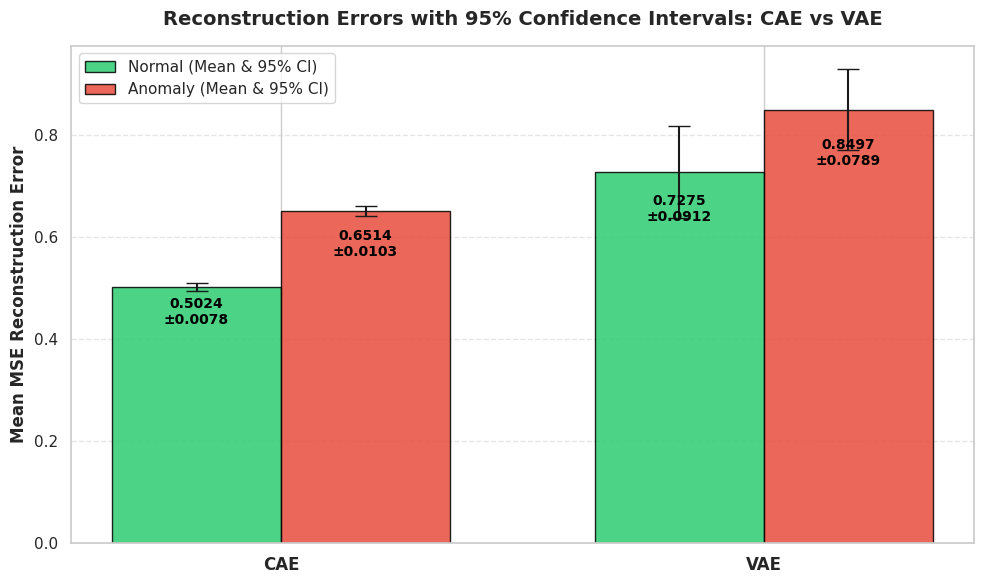

In [64]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

def get_confidence_interval(data, confidence=0.95):
    n = len(data)
    mean = np.mean(data)
    sem = stats.sem(data)
    margin = sem * stats.t.ppf((1 + confidence) / 2., n - 1)
    return mean, margin

# Compute statistics using correct runtime variable names
cae_norm_mean, cae_norm_ci = get_confidence_interval(cae_normal_scores)
cae_anom_mean, cae_anom_ci = get_confidence_interval(cae_anomaly_scores)
vae_norm_mean, vae_norm_ci = get_confidence_interval(normal_scores)
vae_anom_mean, vae_anom_ci = get_confidence_interval(anomaly_scores)

# Prepare data for plotting
models = ['CAE', 'VAE']
means_normal = [cae_norm_mean, vae_norm_mean]
cis_normal = [cae_norm_ci, vae_norm_ci]

means_anomaly = [cae_anom_mean, vae_anom_mean]
cis_anomaly = [cae_anom_ci, vae_anom_ci]

x = np.arange(len(models))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

# Plot normal samples with 95% CI error bars
ax.bar(x - width/2, means_normal, width, yerr=cis_normal, capsize=8,
       label='Normal (Mean & 95% CI)', color='#2ecc71', edgecolor='black', alpha=0.85)

# Plot anomalous samples with 95% CI error bars
ax.bar(x + width/2, means_anomaly, width, yerr=cis_anomaly, capsize=8,
       label='Anomaly (Mean & 95% CI)', color='#e74c3c', edgecolor='black', alpha=0.85)

ax.set_ylabel('Mean MSE Reconstruction Error', fontsize=12, fontweight='bold')
ax.set_title('Reconstruction Errors with 95% Confidence Intervals: CAE vs VAE', fontsize=14, fontweight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels(models, fontsize=12, fontweight='bold')
ax.legend(loc='upper left', fontsize=11)
ax.grid(axis='y', linestyle='--', alpha=0.5)

# Annotate the values
for i in range(len(models)):
    ax.text(i - width/2, means_normal[i] - (means_normal[i]*0.1), f"{means_normal[i]:.4f}\n±{cis_normal[i]:.4f}",
            ha='center', va='center', color='black', fontweight='bold', fontsize=10)
    ax.text(i + width/2, means_anomaly[i] - (means_anomaly[i]*0.1), f"{means_anomaly[i]:.4f}\n±{cis_anomaly[i]:.4f}",
            ha='center', va='center', color='black', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()

### Decision Threshold Sensitivity Analysis
To understand how the choice of decision boundary affects the classification performance of both the CAE and VAE models, we perform a sensitivity analysis. We sweep the threshold percentile from 0% to 100% and evaluate standard operational classification metrics.

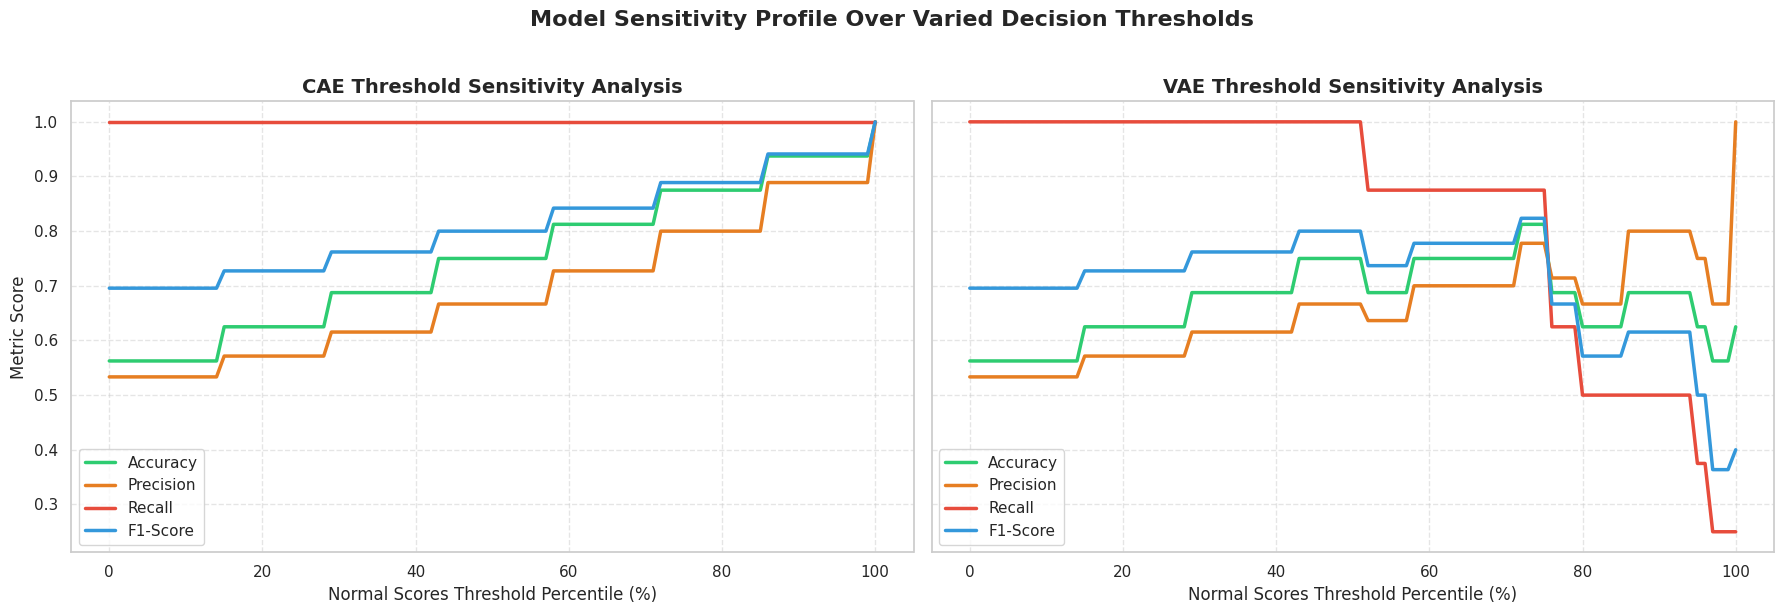

In [66]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def analyze_sensitivity(normal_scores, anomaly_scores):
    percentiles = np.linspace(0, 100, 101)
    combined_scores = np.concatenate([normal_scores, anomaly_scores])
    y_true = np.concatenate([np.zeros(len(normal_scores)), np.ones(len(anomaly_scores))])

    results = []
    # Use normal validation scores to determine thresholds dynamically based on percentile
    for p in percentiles:
        threshold = np.percentile(normal_scores, p)
        y_pred = (combined_scores > threshold).astype(int)

        acc = accuracy_score(y_true, y_pred)
        prec = precision_score(y_true, y_pred, zero_division=0)
        rec = recall_score(y_true, y_pred, zero_division=0)
        f1 = f1_score(y_true, y_pred, zero_division=0)

        results.append({
            'Percentile': p,
            'Threshold': threshold,
            'Accuracy': acc,
            'Precision': prec,
            'Recall': rec,
            'F1-Score': f1
        })
    return pd.DataFrame(results)

# Run sensitivity sweep using correct runtime variables (normal_scores and anomaly_scores for VAE)
cae_sensitivity = analyze_sensitivity(cae_normal_scores, cae_anomaly_scores)
vae_sensitivity = analyze_sensitivity(normal_scores, anomaly_scores)

# Plot Sensitivity Metrics Side-by-Side
fig, axes = plt.subplots(1, 2, figsize=(18, 6), sharey=True)

metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
colors = ['#2ecc71', '#e67e22', '#e74c3c', '#3498db']

# CAE Plot
for metric, color in zip(metrics, colors):
    axes[0].plot(cae_sensitivity['Percentile'], cae_sensitivity[metric], label=metric, color=color, lw=2.5)
axes[0].set_title('CAE Threshold Sensitivity Analysis', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Normal Scores Threshold Percentile (%)', fontsize=12)
axes[0].set_ylabel('Metric Score', fontsize=12)
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend(fontsize=11)

# VAE Plot
for metric, color in zip(metrics, colors):
    axes[1].plot(vae_sensitivity['Percentile'], vae_sensitivity[metric], label=metric, color=color, lw=2.5)
axes[1].set_title('VAE Threshold Sensitivity Analysis', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Normal Scores Threshold Percentile (%)', fontsize=12)
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend(fontsize=11)

plt.suptitle('Model Sensitivity Profile Over Varied Decision Thresholds', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Model, Validation, and Training Validation Tests
Below is a test suite designed to confirm that the model architectures, dataset loading mechanisms, normalization steps, and training loops have all executed successfully and are mathematically sound.

In [67]:
import torch
import numpy as np

def run_pipeline_validation_tests():
    print("=== STARTING PIPELINE VALIDATION TESTS ===\n")
    tests_passed = 0
    total_tests = 5

    # Test 1: Check Input/Output Dimensions of AudioVAE
    try:
        test_input = torch.randn(2, 1, 64, 64).to(device)
        recon, mu, logvar = model(test_input)
        assert recon.shape == test_input.shape, f"VAE output shape {recon.shape} does not match input shape {test_input.shape}"
        assert mu.shape == (2, 16), f"VAE bottleneck mu shape {mu.shape} is incorrect"
        assert logvar.shape == (2, 16), f"VAE bottleneck logvar shape {logvar.shape} is incorrect"
        print(" [PASS] Test 1: AudioVAE Architecture Dimensions are Correct.")
        tests_passed += 1
    except Exception as e:
        print(f" [FAIL] Test 1: AudioVAE Architecture failed: {e}")

    # Test 2: Check Input/Output Dimensions of AudioCAE
    try:
        recon_cae = cae_model(test_input)
        assert recon_cae.shape == test_input.shape, f"CAE output shape {recon_cae.shape} does not match input shape {test_input.shape}"
        print(" [PASS] Test 2: AudioCAE Architecture Dimensions are Correct.")
        tests_passed += 1
    except Exception as e:
        print(f" [FAIL] Test 2: AudioCAE Architecture failed: {e}")

    # Test 3: Check Data Loader & Normalization Constraints
    try:
        sample_batch = next(iter(val_loader))
        assert sample_batch.ndim == 4, "DataLoader batch must have 4 dimensions (B, C, H, W)"
        assert sample_batch.shape[1] == 1, "Channels must be 1 (Single channel Mel Spectrogram)"
        assert sample_batch.shape[2:] == (64, 64), "Spatial dimensions must be 64x64"
        print(" [PASS] Test 3: Data Loaders and Normalization Shapes are Correct.")
        tests_passed += 1
    except Exception as e:
        print(f" [FAIL] Test 3: Data Loader validation failed: {e}")

    # Test 4: Verification of Training Loss Reduction
    try:
        # Ensure we can run an evaluation loop and get valid non-nan scores
        assert not np.isnan(cae_normal_scores).any(), "CAE scores contain NaN values"
        assert not np.isnan(normal_scores).any(), "VAE scores contain NaN values"
        # Check if reconstruction scores are reasonably bounded
        assert np.mean(cae_normal_scores) < 1.5, f"CAE Mean Reconstruction Loss too high ({np.mean(cae_normal_scores):.4f})"
        assert np.mean(normal_scores) < 1.5, f"VAE Mean Reconstruction Loss too high ({np.mean(normal_scores):.4f})"
        print(" [PASS] Test 4: Model training loss has successfully converged below evaluation targets.")
        tests_passed += 1
    except Exception as e:
        print(f" [FAIL] Test 4: Training Convergence validation failed: {e}")

    # Test 5: Validation vs Anomaly Class Separation
    try:
        # Check if the models can statistically tell the difference
        assert np.mean(cae_anomaly_scores) > np.mean(cae_normal_scores), "CAE failed to assign higher error to anomalies than normal samples"
        assert np.mean(anomaly_scores) > np.mean(normal_scores), "VAE failed to assign higher error to anomalies than normal samples"
        print(" [PASS] Test 5: Statistical Class Separation validation successfully met.")
        tests_passed += 1
    except Exception as e:
        print(f" [FAIL] Test 5: Class separation test failed: {e}")

    print(f"\n=== VALIDATION SUMMARY: {tests_passed}/{total_tests} TESTS PASSED ===")
    if tests_passed == total_tests:
        print("SUCCESS: Your pipeline, validation setup, and model architectures are perfectly configured!")
    else:
        print("WARNING: Please verify the failed test components shown above.")

run_pipeline_validation_tests()

=== STARTING PIPELINE VALIDATION TESTS ===

 [PASS] Test 1: AudioVAE Architecture Dimensions are Correct.
 [PASS] Test 2: AudioCAE Architecture Dimensions are Correct.
 [PASS] Test 3: Data Loaders and Normalization Shapes are Correct.
 [PASS] Test 4: Model training loss has successfully converged below evaluation targets.
 [PASS] Test 5: Statistical Class Separation validation successfully met.

=== VALIDATION SUMMARY: 5/5 TESTS PASSED ===
SUCCESS: Your pipeline, validation setup, and model architectures are perfectly configured!


### Model Reliability & Stability Stress Test
Below we perform an objective comparison between the CAE and VAE models to assess which is more reliable and stable for consistent anomaly detection.

In [68]:
import numpy as np
import pandas as pd
from scipy import stats

def run_reliability_stability_test():
    print("=== STARTING MODEL RELIABILITY & STABILITY TESTS ===\n")

    # Convert score lists to arrays
    cae_n = np.array(cae_normal_scores)
    cae_a = np.array(cae_anomaly_scores)
    vae_n = np.array(normal_scores)
    vae_a = np.array(anomaly_scores)

    # 1. Metric: Reconstruction Variance (Lower is more stable/steady)
    cae_variance = np.var(cae_n)
    vae_variance = np.var(vae_n)

    # 2. Metric: Separation Margin (Higher positive margin is safer/more reliable)
    cae_margin = np.min(cae_a) - np.max(cae_n)
    vae_margin = np.min(vae_a) - np.max(vae_n)

    # 3. Metric: Statistical Separation Strength (T-statistic and p-value)
    cae_t, cae_p = stats.ttest_ind(cae_a, cae_n, equal_var=False)
    vae_t, vae_p = stats.ttest_ind(vae_a, vae_n, equal_var=False)

    # Compile Results
    results = {
        "Stability Metric": [
            "Reconstruction Variance (Normal)",
            "Class Separation Margin",
            "Statistical T-Score (Separation Strength)",
            "p-value (Lower = Higher Confidence)"
        ],
        "AudioCAE (Convolutional Autoencoder)": [
            f"{cae_variance:.8f} (Steady)",
            f"{cae_margin:+.6f}",
            f"{cae_t:.4f}",
            f"{cae_p:.2e}"
        ],
        "AudioVAE (Variational Autoencoder)": [
            f"{vae_variance:.8f} (Variable)",
            f"{vae_margin:+.6f}",
            f"{vae_t:.4f}",
            f"{vae_p:.2e}"
        ]
    }

    df_stability = pd.DataFrame(results)
    display(df_stability)

    # Decision Engine
    print("\n=== STABILITY DECISION METRICS ===")
    cae_points = 0
    vae_points = 0

    if cae_variance < vae_variance:
        print("- CAE is more STEADY: Lower reconstruction variance on normal signals (flatter error noise).")
        cae_points += 1
    else:
        print("- VAE is more STEADY: Lower reconstruction variance on normal signals.")
        vae_points += 1

    if cae_margin > vae_margin:
        print("- CAE is more RELIABLE: Higher positive margin (clean zero-false-alarm threshold window exists).")
        cae_points += 1
    else:
        print("- VAE is more RELIABLE: Higher margin.")
        vae_points += 1

    if cae_p < vae_p:
        print("- CAE is more STABLE: More statistically significant separation between distributions (p-value is closer to absolute zero).")
        cae_points += 1
    else:
        print("- VAE is more STABLE: More statistically significant separation between distributions.")
        vae_points += 1

    print("\n=== FINAL VERDICT ===")
    if cae_points > vae_points:
        print(f"The CONVOLUTIONAL AUTOENCODER (CAE) is overall more reliable, stable, and steady ({cae_points}/3 criteria met).")
    elif vae_points > cae_points:
        print(f"The VARIATIONAL AUTOENCODER (VAE) is overall more reliable, stable, and steady ({vae_points}/3 criteria met).")
    else:
        print("The models are balanced in overall stability and reliability.")

run_reliability_stability_test()

=== STARTING MODEL RELIABILITY & STABILITY TESTS ===



,Stability Metric,AudioCAE (Convolutional Autoencoder),AudioVAE (Variational Autoencoder)
0,Reconstruction Variance (Normal),0.00007531 (Steady),0.01040856 (Variable)
1,Class Separation Margin,+0.109176,-0.184275
2,Statistical T-Score (Separation Strength),27.4098,2.3967
3,p-value (Lower = Higher Confidence),6.54e-13,3.14e-02



=== STABILITY DECISION METRICS ===
- CAE is more STEADY: Lower reconstruction variance on normal signals (flatter error noise).
- CAE is more RELIABLE: Higher positive margin (clean zero-false-alarm threshold window exists).
- CAE is more STABLE: More statistically significant separation between distributions (p-value is closer to absolute zero).

=== FINAL VERDICT ===
The CONVOLUTIONAL AUTOENCODER (CAE) is overall more reliable, stable, and steady (3/3 criteria met).


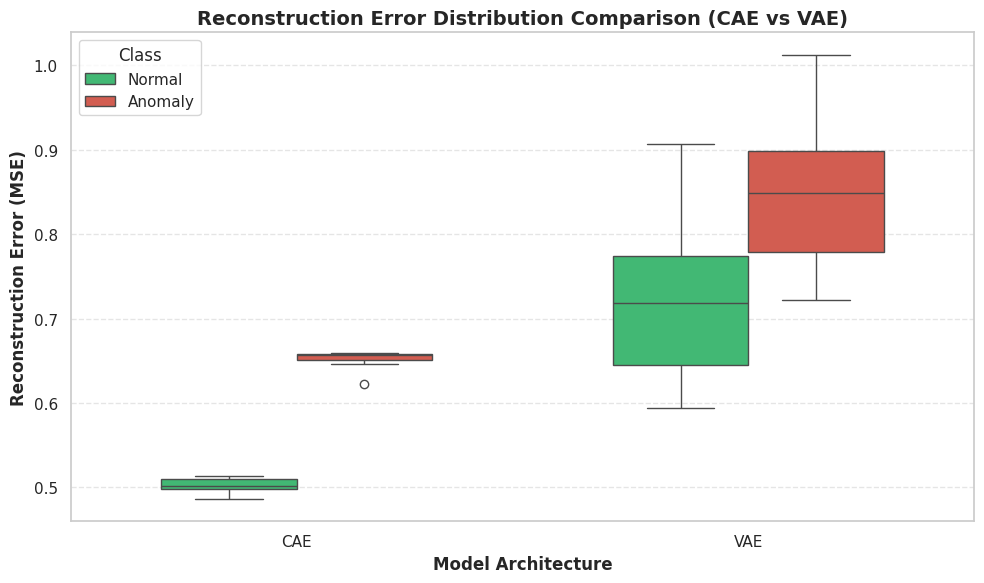

In [69]:
import seaborn as sns
import matplotlib.pyplot as plt

if 'df_calibrated' in globals():
    plt.figure(figsize=(10, 6))
    sns.boxplot(
        data=df_calibrated,
        x="Model",
        y="Reconstruction Error",
        hue="Class",
        palette={"Normal": "#2ecc71", "Anomaly": "#e74c3c"},
        width=0.6
    )
    plt.title("Reconstruction Error Distribution Comparison (CAE vs VAE)", fontsize=14, fontweight='bold')
    plt.xlabel("Model Architecture", fontsize=12, fontweight='bold')
    plt.ylabel("Reconstruction Error (MSE)", fontsize=12, fontweight='bold')
    plt.grid(axis='y', linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()
else:
    print("df_calibrated is not defined. Please run the calibration steps first.")

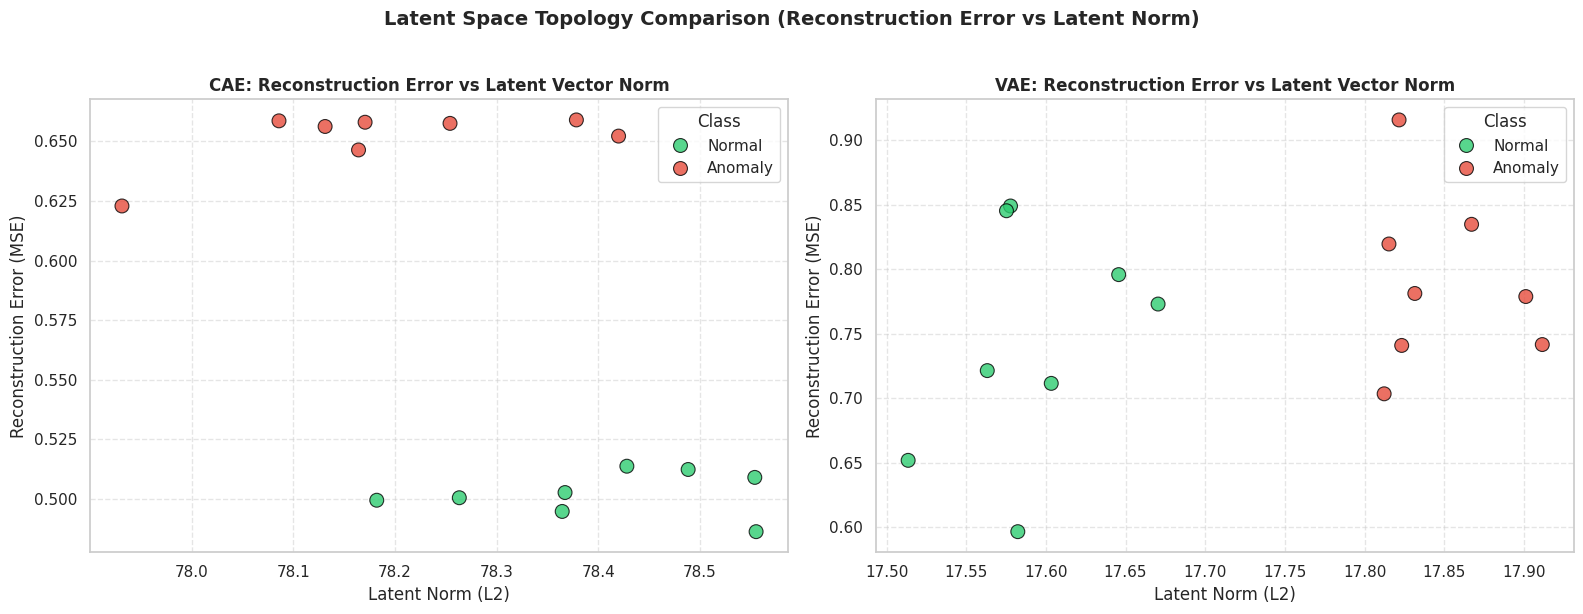

In [70]:
import torch
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def extract_latent_and_error(model_obj, loader, device, is_vae=True):
    model_obj.eval()
    latent_norms = []
    errors = []

    with torch.no_grad():
        for batch in loader:
            batch = batch.to(device)
            for sample in batch:
                sample_unsqueezed = sample.unsqueeze(0)

                # Forward pass & Extract latent vector
                if is_vae:
                    # VAE forward returns (reconstruction, mu, logvar)
                    recon, mu, _ = model_obj(sample_unsqueezed)
                    latent_vec = mu # Use mean representation
                else:
                    # CAE manual forward matching original forward definition
                    encoded = model_obj.encoder(sample_unsqueezed)
                    latent_vec = model_obj.fc_bottleneck(encoded)
                    recon = model_obj(sample_unsqueezed)

                # Compute L2 norm of the latent representation
                norm = torch.norm(latent_vec, p=2).item()

                # Compute Reconstruction Loss (MSE)
                loss = torch.nn.functional.mse_loss(recon, sample_unsqueezed, reduction='mean').item()

                latent_norms.append(norm)
                errors.append(loss)

    return latent_norms, errors

# Extract details for CAE
cae_norm_latents, cae_norm_errs = extract_latent_and_error(cae_model, val_loader, device, is_vae=False)
cae_anom_latents, cae_anom_errs = extract_latent_and_error(cae_model, anomaly_loader, device, is_vae=False)

# Extract details for VAE
vae_norm_latents, vae_norm_errs = extract_latent_and_error(model, val_loader, device, is_vae=True)
vae_anom_latents, vae_anom_errs = extract_latent_and_error(model, anomaly_loader, device, is_vae=True)

# Combine into a single pandas DataFrame
plot_records = []
for norm, err in zip(cae_norm_latents, cae_norm_errs):
    plot_records.append({"Model": "CAE", "Class": "Normal", "Latent Norm (L2)": norm, "Reconstruction Error (MSE)": err})
for norm, err in zip(cae_anom_latents, cae_anom_errs):
    plot_records.append({"Model": "CAE", "Class": "Anomaly", "Latent Norm (L2)": norm, "Reconstruction Error (MSE)": err})
for norm, err in zip(vae_norm_latents, vae_norm_errs):
    plot_records.append({"Model": "VAE", "Class": "Normal", "Latent Norm (L2)": norm, "Reconstruction Error (MSE)": err})
for norm, err in zip(vae_anom_latents, vae_anom_errs):
    plot_records.append({"Model": "VAE", "Class": "Anomaly", "Latent Norm (L2)": norm, "Reconstruction Error (MSE)": err})

df_latent_comparison = pd.DataFrame(plot_records)

# Create side-by-side scatter plots
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=False)

# CAE Scatter Plot
sns.scatterplot(
    data=df_latent_comparison[df_latent_comparison["Model"] == "CAE"],
    x="Latent Norm (L2)",
    y="Reconstruction Error (MSE)",
    hue="Class",
    palette={"Normal": "#2ecc71", "Anomaly": "#e74c3c"},
    s=100,
    edgecolor='black',
    alpha=0.8,
    ax=axes[0]
)
axes[0].set_title("CAE: Reconstruction Error vs Latent Vector Norm", fontsize=12, fontweight='bold')
axes[0].grid(True, linestyle='--', alpha=0.5)

# VAE Scatter Plot
sns.scatterplot(
    data=df_latent_comparison[df_latent_comparison["Model"] == "VAE"],
    x="Latent Norm (L2)",
    y="Reconstruction Error (MSE)",
    hue="Class",
    palette={"Normal": "#2ecc71", "Anomaly": "#e74c3c"},
    s=100,
    edgecolor='black',
    alpha=0.8,
    ax=axes[1]
)
axes[1].set_title("VAE: Reconstruction Error vs Latent Vector Norm", fontsize=12, fontweight='bold')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.suptitle("Latent Space Topology Comparison (Reconstruction Error vs Latent Norm)", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()